In [1]:
import sys; sys.path.append("..")
import pandas as pd
from src.data import load_data
from src.evaluation import cv_evaluate, summarize
from src.pipelines import get_classic

X_train, _, y_train, _, labels = load_data()

res = []
for name, model in get_classic().items():
    print("Dang chay:", name)
    res.append(cv_evaluate(model, X_train, y_train, name))

summ = summarize(pd.concat(res))
summ

Dang chay: knn_k5
Dang chay: decision_tree
Dang chay: random_forest


macro_f1         balanced_acc             mcc         accuracy  \
                  mean     std         mean     std    mean     std     mean   
model                                                                          
decision_tree   0.9405  0.0109       0.9503  0.0227  0.9939  0.0003   0.9975   
knn_k5          0.9467  0.0109       0.9361  0.0242  0.9904  0.0009   0.9961   
random_forest   0.9617  0.0129       0.9541  0.0161  0.9957  0.0004   0.9983   

                      weighted_f1         fit_time          
                  std        mean     std     mean     std  
model                                                       
decision_tree  0.0001      0.9975  0.0001   2.5040  0.7418  
knn_k5         0.0004      0.9961  0.0003   0.4956  0.3228  
random_forest  0.0002      0.9983  0.0002   4.5119  0.3279

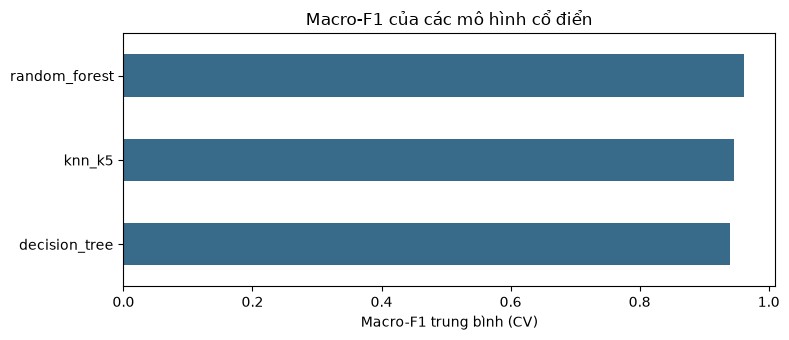

In [2]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

results = (Path('..') if Path.cwd().name == 'experiments' else Path('.')) / 'results'
models = ['knn_k5', 'decision_tree', 'random_forest']
values = pd.concat([pd.read_csv(results / f'cv/{name}.csv') for name in models]).groupby('model')['macro_f1'].mean()
fig, ax = plt.subplots(figsize=(8, 3.5))
values.sort_values().plot.barh(ax=ax, color='#386A89')
ax.set(title='Macro-F1 của các mô hình cổ điển', xlabel='Macro-F1 trung bình (CV)', ylabel='')
fig.tight_layout()
(results / 'figures').mkdir(exist_ok=True)
fig.savefig(results / 'figures/classic_models_macro_f1.png', dpi=300, bbox_inches='tight')
plt.show()

In [4]:
import sys; sys.path.append("..")
from src.data import load_data
from src.pipelines import get_classic
from src.experiment_log import ExperimentLogger, export_excel

X_train, _, y_train, _, labels = load_data()
lg = ExperimentLogger("tuan")  

# Vòng lặp chạy tất cả các mô hình classic và ghi nhật ký tự động
for name, model in get_classic().items():
    lg.run(model, X_train, y_train, name)

# Xuất file tổng hợp toàn bộ kết quả của nhóm ra Excel
export_excel()
print("Đã chạy xong các mô hình cơ bản và xuất log ra Excel!")

Đã chạy xong các mô hình cơ bản và xuất log ra Excel!
